# 03 · Ritmo de pagos y acople

$\dot\theta_i = \omega_i + \frac{K}{\langle k\rangle}\sum_j W_{ij}\sin(\theta_j-\theta_i)$; el ingreso desfasado crea déficit $\gamma k_i(1-r_i)$.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

FIG = Path("..") / "figures"
FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
TOPO_LABEL = {"erdos_renyi": "Erdős–Rényi", "barabasi_albert": "Barabási–Albert",
              "core_periphery": "Núcleo-periferia"}

In [2]:
from finnet.networks import NetworkConfig, generate

def_cfg = dict(n=200, mean_degree=6.0, amount_sigma=0.8, core_frac=0.1, p_core=0.8,
               periphery_share=0.1, seed=1)
nets = {t: generate(NetworkConfig(topology=t, **def_cfg)) for t in TOPO_LABEL}

## Curvas $r(K)$ por topología

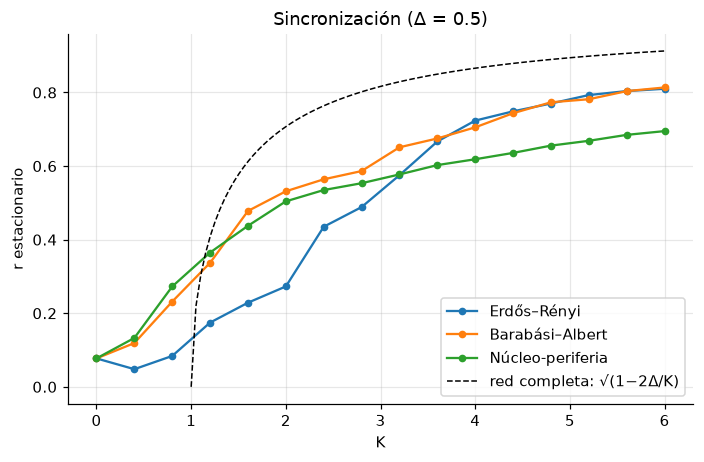

In [3]:
from finnet.integrate import simulate
from finnet.metrics import order_parameter
from finnet.model import Params, lorentz_frequencies

DELTA = 0.5
Ks = np.linspace(0, 6, 16)
def steady_r(W, K, seed=0):
    rng = np.random.default_rng(seed)
    om = rng.permutation(lorentz_frequencies(W.shape[0], 0.0, DELTA))
    tr = simulate(W, Params(alpha=1, beta=0, K=K, omega=om), t_end=40, dt=0.05,
                  theta0=rng.uniform(0, 2*np.pi, W.shape[0]), save_every=10)
    r = order_parameter(tr.theta)
    return r[tr.t > 20].mean()

curves = {t: [steady_r(W, K) for K in Ks] for t, W in nets.items()}
fig, ax = plt.subplots(figsize=(6.5, 4.3))
for t, r in curves.items():
    ax.plot(Ks, r, "o-", ms=4, label=TOPO_LABEL[t])
Kth = np.linspace(2 * DELTA, Ks[-1], 100)
ax.plot(Kth, np.sqrt(1 - 2 * DELTA / Kth), "k--", lw=1, label="red completa: √(1−2Δ/K)")
ax.set(xlabel="K", ylabel="r estacionario", title=f"Sincronización (Δ = {DELTA})"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "fase3_r_vs_K.png")

## Estimación de $K_c$
Primer $K$ donde $r$ supera 0.3 (umbral práctico de tamaño finito).

In [4]:
pd.DataFrame({TOPO_LABEL[t]: [Ks[np.argmax(np.array(r) > 0.3)] if max(r) > 0.3 else np.nan]
              for t, r in curves.items()}, index=["K_c estimado"])

,Erdős–Rényi,Barabási–Albert,Núcleo-periferia
K_c estimado,2.4,1.2,1.2


## Caída de $r$ al retirar la entidad más central y déficit generado

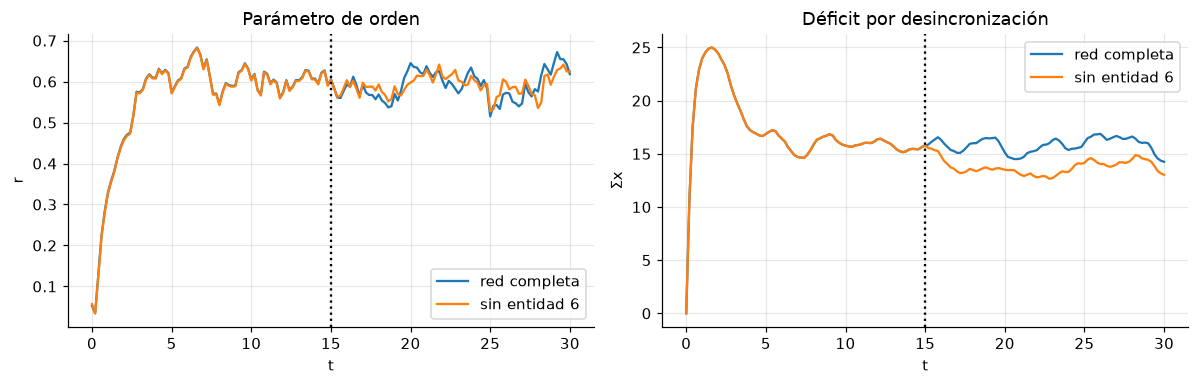

In [5]:
from finnet import service
from finnet.spectral import entity_ranking

W = nets["core_periphery"]; n = W.shape[0]
rng = np.random.default_rng(1)
p = Params(alpha=1.0, beta=0.0, K=4.0, gamma=0.05,
           omega=rng.permutation(lorentz_frequencies(n, 2*np.pi, DELTA)))
sim = {"dt": 0.02, "t_end": 30.0, "save_every": 10}
theta0 = rng.uniform(0, 2*np.pi, n)
hub = int(entity_ranking(W)["entidad"].iloc[0])
base = service.rhythm_run(W, p, sim, theta0)
cut = service.rhythm_run(W, p, sim, theta0, disconnect=hub, t_disconnect=15.0)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(base["t"], base["r"], label="red completa"); ax[0].plot(cut["t"], cut["r"], label=f"sin entidad {hub}")
ax[0].axvline(15, c="k", ls=":"); ax[0].set(xlabel="t", ylabel="r", title="Parámetro de orden"); ax[0].legend()
ax[1].plot(base["t"], base["deficit"], label="red completa"); ax[1].plot(cut["t"], cut["deficit"], label=f"sin entidad {hub}")
ax[1].axvline(15, c="k", ls=":"); ax[1].set(xlabel="t", ylabel="Σx", title="Déficit por desincronización"); ax[1].legend()
fig.tight_layout(); fig.savefig(FIG / "fase3_desconexion.png")